  # <b><font color='black'>Market Basket Analysis</font></b>
---

- Task : Association Rules
- Objective : Menemukan Hubungan (association) Antara Item-Item Dalam Transaksi.

![](https://blog.rsquaredacademy.com/img/mba_steps.png)

# **Importing All Necessary Python Libraries**

In [1]:
# Data Manipulaton
import pandas as pd
import numpy as np
import datetime as dt

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Preprocessing
from scipy import stats

# Modelling
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

# Warning Detection
import warnings
warnings.filterwarnings("ignore")
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

In [2]:
url = "https://raw.githubusercontent.com/agungibr/Bussiness-Analytics/refs/heads/main/dataset/Online%20Retail%20Data.csv"

df = pd.read_csv(url)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 461773 entries, 0 to 461772
Data columns (total 7 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   order_id      461773 non-null  object 
 1   product_code  461773 non-null  object 
 2   product_name  459055 non-null  object 
 3   quantity      461773 non-null  int64  
 4   order_date    461773 non-null  object 
 5   price         461773 non-null  float64
 6   customer_id   360853 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 24.7+ MB


# Data Cleaning

In [4]:
df_clean = df.copy()

In [5]:
# Membuat kolom date
df_clean['date'] = pd.to_datetime(df_clean['order_date'])

In [6]:
# menghapus semua baris tanpa customer_id
df_clean = df_clean[~df_clean['customer_id'].isna()]

In [7]:
# mengkonversi customer_id menjadi string
df_clean['customer_id'] = df_clean['customer_id'].astype(str)

In [8]:
# menghapus semua baris tanpa product_name
df_clean = df_clean[~df_clean['product_name'].isna()]

In [9]:
# membuat semua product_name berhuruf kecil
df_clean['product_name'] = df_clean['product_name'].str.lower()

In [10]:
# menghapus semua baris dengan product_code atau product_name test
df_clean = df_clean[(~df_clean['product_code'].str.lower().str.contains('test')) |
                    (~df_clean['product_name'].str.contains('test '))]

In [11]:
# menghapus baris dengan status cancelled, yaitu yang order_id-nya diawali 'C'
df_clean = df_clean[df_clean['order_id'].str[:1]!='C']

In [12]:
# mengubah nilai quantity yang negatif menjadi positif karena nilai negatif tersebut hanya menandakan order tersebut cancelled
df_clean['quantity'] = df_clean['quantity'].abs()

In [13]:
# menghapus baris dengan price bernilai negatif
df_clean = df_clean[df_clean['price'] > 0]

In [14]:
# membuat nilai amount, yaitu perkalian antara quantity dan price
df_clean['amount'] = df_clean['quantity'] * df_clean['price']

In [15]:
# mengganti product_name dari product_code yang memiliki beberapa product_name dengan salah satu product_name-nya yang paling sering muncul
most_freq_product_name = df_clean.groupby(['product_code','product_name'], as_index=False).agg(order_cnt=('order_id','nunique')).sort_values(['product_code','order_cnt'], ascending=[True,False])
most_freq_product_name['rank'] = most_freq_product_name.groupby('product_code')['order_cnt'].rank(method='first', ascending=False)
most_freq_product_name = most_freq_product_name[most_freq_product_name['rank']==1].drop(columns=['order_cnt','rank'])
df_clean = df_clean.merge(most_freq_product_name.rename(columns={'product_name':'most_freq_product_name'}), how='left', on='product_code')
df_clean['product_name'] = df_clean['most_freq_product_name']
df_clean = df_clean.drop(columns='most_freq_product_name')

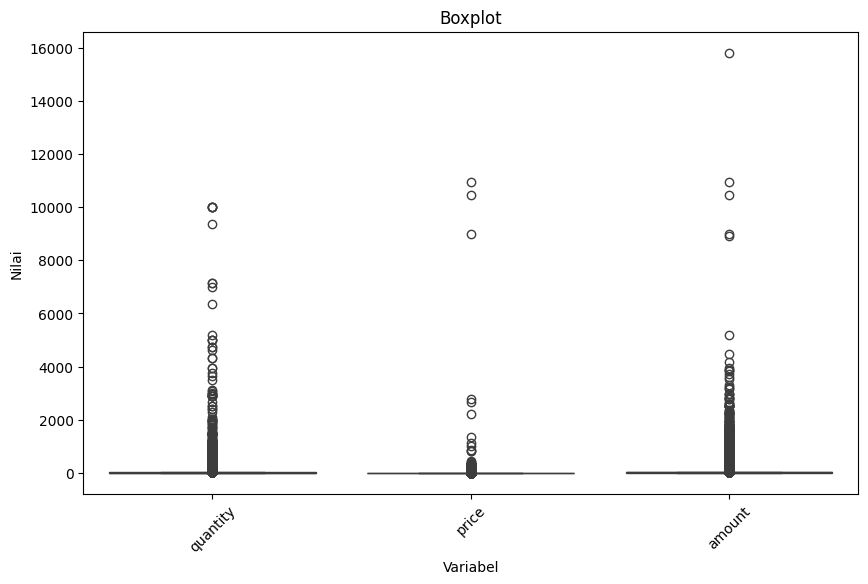

In [16]:
# Ambil kolom bertipe numerik (int dan float)
num_cols = df_clean.select_dtypes(include=['int64', 'float64']).columns

# Boxplot
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_clean[num_cols])
plt.title("Boxplot")
plt.xlabel("Variabel")
plt.ylabel("Nilai")
plt.xticks(rotation=45)
plt.show()

In [17]:
# menghapus outlier
df_clean = df_clean[(np.abs(stats.zscore(df_clean[['quantity','amount']])) < 3).all(axis=1)]
df_clean = df_clean.reset_index(drop=True)
df_clean.head()

,order_id,product_code,product_name,quantity,order_date,price,customer_id,date,amount
0,493414,21844,red retrospot mug,36,2010-01-04 10:28:00,2.55,14590.0,2010-01-04 10:28:00,91.8
1,493414,21533,retro spot large milk jug,12,2010-01-04 10:28:00,4.25,14590.0,2010-01-04 10:28:00,51.0
2,493414,37508,new england ceramic cake server,2,2010-01-04 10:28:00,2.55,14590.0,2010-01-04 10:28:00,5.1
3,493414,35001G,hand open shape gold,2,2010-01-04 10:28:00,4.25,14590.0,2010-01-04 10:28:00,8.5
4,493414,21527,red retrospot traditional teapot,12,2010-01-04 10:28:00,6.95,14590.0,2010-01-04 10:28:00,83.4


In [18]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 350092 entries, 0 to 350091
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   order_id      350092 non-null  object        
 1   product_code  350092 non-null  object        
 2   product_name  350092 non-null  object        
 3   quantity      350092 non-null  int64         
 4   order_date    350092 non-null  object        
 5   price         350092 non-null  float64       
 6   customer_id   350092 non-null  object        
 7   date          350092 non-null  datetime64[ns]
 8   amount        350092 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(1), object(5)
memory usage: 24.0+ MB


# Basket Analysis

In [19]:
# Buat dataframe basket
basket = pd.pivot_table(df_clean, index='order_id', columns='product_name', values='product_code', aggfunc='nunique', fill_value=0)
basket

product_name  10 colour spaceboy pen  12 ass zinc christmas decorations  \
order_id                                                                  
493414                             0                                  0   
493427                             0                                  0   
493428                             0                                  0   
493432                             0                                  0   
493433                             0                                  0   
...                              ...                                ...   
539981                             0                                  0   
539982                             0                                  0   
539985                             0                                  0   
539987                             0                                  0   
539988                             0                                  0   

product_name  12 coloured party balloons  12 daisy pegs in wood box  \
order_id                                                              
493414                                 0                          0   
493427                                 0                          0   
493428                                 0                          0   
493432                                 0                          0   
493433                                 0                          0   
...                                  ...                        ...   
539981                                 0                          0   
539982                                 0                          0   
539985                                 0                          0   
539987                                 0                          0   
539988                                 0                          0   

product_name  12 egg house painted wood  12 ivory rose peg place settings  \
order_id                                                                    
493414                                0                                 0   
493427                                0                                 0   
493428                                0                                 0   
493432                                0                                 0   
493433                                0                                 0   
...                                 ...                               ...   
539981                                0                                 0   
539982                                0                                 0   
539985                                0                                 0   
539987                                0                                 0   
539988                                0                                 0   

product_name  12 message cards with envelopes  12 mini toadstool pegs  \
order_id                                                                
493414                                      0                       0   
493427                                      0                       0   
493428                                      0                       0   
493432                                      0                       0   
493433                                      0                       0   
...                                       ...                     ...   
539981                                      0                       0   
539982                                      0                       0   
539985                                      0                       0   
539987                                      0                       0   
539988                                      0                       0   

product_name  12 pencil small tube woodland  12 pencils small tube posy  \
order_id                                                                 

In [20]:
basket.info()

<class 'pandas.core.frame.DataFrame'>
Index: 16272 entries, 493414 to 539988
Columns: 3842 entries, 10 colour spaceboy pen to zinc willie winkie  candle stick
dtypes: int64(3842)
memory usage: 477.1+ MB


In [21]:
# Encode DataFrame basket dengan nilai True untuk semua nilai di atas 0 dan False untuk semua nilai 0
def encode(x):
    if x == 0:
        return False
    if x > 0:
        return True

basket_encode = basket.applymap(encode)
basket_encode.head()

product_name  10 colour spaceboy pen  12 ass zinc christmas decorations  \
order_id                                                                  
493414                         False                              False   
493427                         False                              False   
493428                         False                              False   
493432                         False                              False   
493433                         False                              False   

product_name  12 coloured party balloons  12 daisy pegs in wood box  \
order_id                                                              
493414                             False                      False   
493427                             False                      False   
493428                             False                      False   
493432                             False                      False   
493433                             False                      False   

product_name  12 egg house painted wood  12 ivory rose peg place settings  \
order_id                                                                    
493414                            False                             False   
493427                            False                             False   
493428                            False                             False   
493432                            False                             False   
493433                            False                             False   

product_name  12 message cards with envelopes  12 mini toadstool pegs  \
order_id                                                                
493414                                  False                   False   
493427                                  False                   False   
493428                                  False                   False   
493432                                  False                   False   
493433                                  False                   False   

product_name  12 pencil small tube woodland  12 pencils small tube posy  \
order_id                                                                  
493414                                False                       False   
493427                                False                       False   
493428                                False                       False   
493432                                False                       False   
493433                                False                       False   

product_name  12 pencils small tube red spotty  12 pencils small tube skull  \
order_id                                                                      
493414                                   False                        False   
493427                                   False                        False   
493428                                   False                        False   
493432                                   False                        False   
493433                                   False                        False   

product_name  12 pencils tall tube posy  12 pencils tall tube red spotty  \
order_id                                                                   
493414                            False                            False   
493427                            False                            False   
493428                            False                            False   
493432                            False                            False   
493433                            False                            False   

product_name  12 pencils tall tube skulls  12 pencils tall tube woodland  \
order_id                                                                   
493414                              False                          False   
493427                              False                          False   
493428 

In [22]:
basket_encode.info()

<class 'pandas.core.frame.DataFrame'>
Index: 16272 entries, 493414 to 539988
Columns: 3842 entries, 10 colour spaceboy pen to zinc willie winkie  candle stick
dtypes: bool(3842)
memory usage: 59.7+ MB


In [23]:
# Ambil transaksi dengan banyaknya produk unik lebih dari 1 saja
basket_filter = basket_encode[(basket_encode > 0).sum(axis=1) > 1]
basket_filter.head()

product_name  10 colour spaceboy pen  12 ass zinc christmas decorations  \
order_id                                                                  
493414                         False                              False   
493427                         False                              False   
493428                         False                              False   
493432                         False                              False   
493433                         False                              False   

product_name  12 coloured party balloons  12 daisy pegs in wood box  \
order_id                                                              
493414                             False                      False   
493427                             False                      False   
493428                             False                      False   
493432                             False                      False   
493433                             False                      False   

product_name  12 egg house painted wood  12 ivory rose peg place settings  \
order_id                                                                    
493414                            False                             False   
493427                            False                             False   
493428                            False                             False   
493432                            False                             False   
493433                            False                             False   

product_name  12 message cards with envelopes  12 mini toadstool pegs  \
order_id                                                                
493414                                  False                   False   
493427                                  False                   False   
493428                                  False                   False   
493432                                  False                   False   
493433                                  False                   False   

product_name  12 pencil small tube woodland  12 pencils small tube posy  \
order_id                                                                  
493414                                False                       False   
493427                                False                       False   
493428                                False                       False   
493432                                False                       False   
493433                                False                       False   

product_name  12 pencils small tube red spotty  12 pencils small tube skull  \
order_id                                                                      
493414                                   False                        False   
493427                                   False                        False   
493428                                   False                        False   
493432                                   False                        False   
493433                                   False                        False   

product_name  12 pencils tall tube posy  12 pencils tall tube red spotty  \
order_id                                                                   
493414                            False                            False   
493427                            False                            False   
493428                            False                            False   
493432                            False                            False   
493433                            False                            False   

product_name  12 pencils tall tube skulls  12 pencils tall tube woodland  \
order_id                                                                   
493414                              False                          False   
493427                              False                          False   
493428 

In [24]:
basket_filter.info()

<class 'pandas.core.frame.DataFrame'>
Index: 15004 entries, 493414 to 539988
Columns: 3842 entries, 10 colour spaceboy pen to zinc willie winkie  candle stick
dtypes: bool(3842)
memory usage: 55.1+ MB


# Apriori Algorithm

In [25]:
# Buat list frequent itemset (kumpulan produk yang sering dibeli)
frequent_itemset = apriori(basket_filter, min_support=.01,
                           use_colnames=True).sort_values('support',
                                                          ascending=False).reset_index(drop=True)
frequent_itemset['product_cnt'] = frequent_itemset['itemsets'].apply(lambda x: len(x))
frequent_itemset.head()

,support,itemsets,product_cnt
0,0.177953,(white hanging heart t-light holder),1
1,0.099440,(regency cakestand 3 tier),1
2,0.096841,(jumbo bag red retrospot),1
3,0.079912,(pack of 72 retro spot cake cases),1
4,0.078512,(assorted colour bird ornament),1


In [26]:
# Hitung nilai support, confidence, dan lift dari setiap pasangan produk yang mungkin
product_association = association_rules(frequent_itemset, metric='confidence',
                                        min_threshold=.7).sort_values(['support','confidence'],
                                                                      ascending=[False,False]).reset_index(drop=True)
product_association.head()

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,(red hanging heart t-light holder),(white hanging heart t-light holder),0.058784,0.177953,0.042455,0.722222,4.058510,1.0,0.031995,2.959371,0.800671,0.218525,0.662090,0.480400
1,(sweetheart ceramic trinket box),(strawberry ceramic trinket box),0.049254,0.074980,0.037457,0.760487,10.142533,1.0,0.033764,3.862089,0.948103,0.431644,0.741073,0.630021
2,(toilet metal sign),(bathroom metal sign),0.026993,0.040589,0.021728,0.804938,19.831353,1.0,0.020632,4.918499,0.975918,0.473837,0.796686,0.670121
3,(red retrospot sugar jam bowl),(red retrospot small milk jug),0.023660,0.037123,0.016796,0.709859,19.121592,1.0,0.015917,3.318652,0.970669,0.381818,0.698673,0.581141
4,(painted metal pears assorted),(assorted colour bird ornament),0.021927,0.078512,0.016596,0.756839,9.639738,1.0,0.014874,3.789618,0.916356,0.197933,0.736121,0.484107


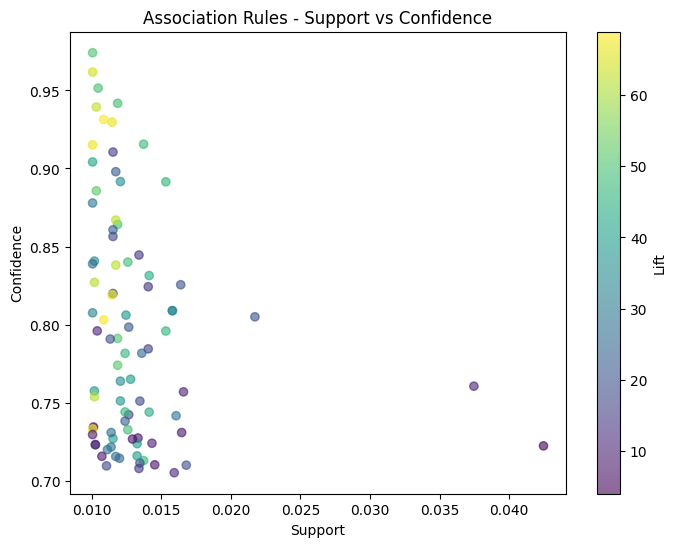

In [27]:
# Plot 2D
plt.figure(figsize=(8,6))
plt.scatter(product_association['support'],
            product_association['confidence'],
            alpha=0.6, c=product_association['lift'], cmap='viridis')

plt.colorbar(label='Lift')
plt.title('Association Rules - Support vs Confidence')
plt.xlabel('Support')
plt.ylabel('Confidence')
plt.show()

In [28]:
# Plot 3D
product_association['antecedents'] = product_association['antecedents'].apply(lambda x: ', '.join(list(x)))
product_association['consequents'] = product_association['consequents'].apply(lambda x: ', '.join(list(x)))

fig = px.scatter_3d(product_association,
                    x='support',
                    y='confidence',
                    z='lift',
                    color='lift',
                    size='lift',
                    hover_data=['antecedents', 'consequents'],
                    title='3D Plot of Association Rules')

fig.show()